# Uplift on existing homes

> How much the tunnel would add to the value of homes already there.

1. **Sales.** Land Registry Price Paid sales since 2018 in SE16, SE8, E14 and E1W, geocoded to
   postcode centroids, with before/after travel times from notebook 03.
2. **Hedonic model.** Regress log price on log travel time to Canary Wharf, controlling for
   property type, new build, tenure, year of sale and distance to the river. The coefficient on
   log time is the elasticity of price with respect to access time.
3. **Uplift.** Apply that elasticity to the tunnel's time savings for every Census 2021 output
   area, valuing each area's homes at the median price of nearby recent sales.

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from tunnel.access import attach_access
from tunnel.config import BNG, COLOURS, DERIVED, FIGURES, WGS84, use_style
from tunnel.data import MSOA_BOUNDARIES, OA_CENTROIDS, geocode, households, ons_layer, price_paid, thames

use_style()

DISTRICTS = ["SE16", "SE8", "E14", "E1W"]
SALES_FROM = "2018-01-01"

## Sales

Only "standard" (category A) sales are kept, which drops repossessions, buy-to-let portfolio and
other non-market transfers.

In [ ]:
sales = pd.concat([price_paid(d, SALES_FROM) for d in DISTRICTS], ignore_index=True)
# The API matches on postcode prefix, so keep exact districts only
sales["district"] = sales["postcode"].str.split().str[0]
sales = sales[sales["district"].isin(DISTRICTS)]
sales = sales[(sales["transaction_category"] == "A") & sales["property_type"].isin(list("DSTF"))]
sales["price"] = sales["price_paid"].astype(int)
sales["date"] = pd.to_datetime(sales["deed_date"])
sales["year"] = sales["date"].dt.year
sales = sales.drop_duplicates("unique_id")

sales = sales.merge(geocode(sales["postcode"].dropna().unique().tolist()), on="postcode", how="left")
print(f"Geocoded {sales.lon.notna().mean():.1%} of sales (terminated postcodes are the usual gap)")
sales = sales.dropna(subset=["lon"])
sales = attach_access(gpd.GeoDataFrame(sales, geometry=gpd.points_from_xy(sales.lon, sales.lat), crs=WGS84))
keep = ["unique_id", "price", "date", "year", "postcode", "district", "property_type", "new_build", "estate_type"]
sales = sales[keep + [c for c in sales.columns if c.endswith(("_before", "_after"))] + ["geometry"]]
sales.drop(columns="geometry").to_csv(DERIVED / "sales.csv", index=False)
print(f"{len(sales):,} standard residential sales since {SALES_FROM}")
sales.groupby(["district", "property_type"]).price.agg(["size", "median"]).unstack()

Geocoded 100.0% of sales (terminated postcodes are the usual gap)


20,926 standard residential sales since 2018-01-01


size                     median                              
property_type    D      F   S    T          D         F         S         T
district                                                                   
E14              3  11931  44  525  1200000.0  525000.0  792500.0  687000.0
E1W              5   1969   3  104  1125000.0  686226.0  900000.0  872475.0
SE16             9   3376  66  534   645000.0  450000.0  722500.0  705000.0
SE8              4   2006  20  327   793500.0  400000.0  720000.0  637500.0

## Hedonic regressions

In [ ]:
river = thames().union_all()
sales["log_price"] = np.log(sales.price)
sales["log_access"] = np.log(sales.access_before)
# "Multimodal" access treats cycling as available to everyone: min(walk/PT, cycle)
sales["log_multimodal"] = np.log(np.minimum(sales.access_before, sales.cycle_before))
sales["log_river"] = np.log(sales.distance(river))

CONTROLS = "C(property_type) + C(new_build) + C(estate_type) + C(year) + log_river"
SPECS = {
    "A: access": "log_access",
    "B: access + district FE": "log_access + C(district)",
    "C: multimodal + district FE": "log_multimodal + C(district)",
}
models = {
    name: smf.ols(f"log_price ~ {rhs} + {CONTROLS}", sales).fit(
        cov_type="cluster", cov_kwds={"groups": sales.postcode}
    )
    for name, rhs in SPECS.items()
}
elasticity = {name: m.params.get("log_access", m.params.get("log_multimodal")) for name, m in models.items()}
pd.DataFrame(
    {
        name: {
            "elasticity: access time": elasticity[name],
            "  (s.e.)": m.bse.get("log_access", m.bse.get("log_multimodal")),
            "elasticity: river distance": m.params["log_river"],
            "R²": m.rsquared,
            "n": int(m.nobs),
        }
        for name, m in models.items()
    }
).round(3)

,A: access,B: access + district FE,C: multimodal + district FE
elasticity: access time,-0.187,-0.310,-0.261
(s.e.),0.027,0.028,0.032
elasticity: river distance,-0.157,-0.129,-0.108
R²,0.266,0.328,0.322
n,20926.000,20926.000,20926.000


## Housing stock by output area

In [ ]:
oa = attach_access(ons_layer(OA_CENTROIDS).merge(households(), on="OA21CD"))
msoa = ons_layer(MSOA_BOUNDARIES).to_crs(BNG)
oa = gpd.sjoin(oa, msoa[["MSOA21NM", "geometry"]], predicate="within").drop(columns="index_right")
oa["borough"] = oa["MSOA21NM"].str.rsplit(" ", n=1).str[0]

# Local value: median price of 2022+ sales within 500 m of the OA centroid
recent = sales[sales.year >= 2022][["price", "geometry"]]
near = gpd.sjoin(oa[["OA21CD", "geometry"]].assign(geometry=oa.buffer(500)), recent, predicate="contains")
oa["median_price"] = oa["OA21CD"].map(near.groupby("OA21CD").price.median())
print(
    f"{oa.median_price.notna().sum()} of {len(oa)} OAs have nearby 2022+ sales; the rest (outside the sales districts) are dropped"
)
oa = oa[oa.median_price.notna()].copy()
oa["stock_value"] = oa.households * oa.median_price
print(f"Stock: {oa.households.sum():,.0f} households worth ~£{oa.stock_value.sum() / 1e9:.1f}bn")

980 of 1439 OAs have nearby 2022+ sales; the rest (outside the sales districts) are dropped
Stock: 130,970 households worth ~£65.1bn


## Uplift scenarios

| Scenario | Uses |
| -------- | ---- |
| Low      | spec A elasticity, walk/PT time only |
| Central  | spec B elasticity, walk/PT time only |
| High     | spec C elasticity, multimodal time (cycling open to everyone) |

The central case is the one the blog uses. The high case assumes everyone would cycle, which
spreads the benefit over a much larger area and is best read as an upper bound.

In [ ]:
def uplift_pct(df, b, multimodal=False):
    if multimodal:
        before = np.minimum(df.access_before, df.cycle_before)
        after = np.minimum(df.access_after, df.cycle_after)
    else:
        before, after = df.access_before, df.access_after
    return (after / before) ** b - 1


scenarios = {
    "Low": uplift_pct(oa, elasticity["A: access"]),
    "Central": uplift_pct(oa, elasticity["B: access + district FE"]),
    "High": uplift_pct(oa, elasticity["C: multimodal + district FE"], multimodal=True),
}
for name, pct in scenarios.items():
    oa[f"uplift_pct_{name}"] = pct
    oa[f"uplift_gbp_{name}"] = pct * oa.stock_value

pd.DataFrame(
    {
        name: {
            "total uplift (£m)": oa[f"uplift_gbp_{name}"].sum() / 1e6,
            **{f"  of which {b} (£m)": v / 1e6 for b, v in oa.groupby("borough")[f"uplift_gbp_{name}"].sum().items()},
            "households with ≥1% uplift": int(oa.loc[oa[f"uplift_pct_{name}"] >= 0.01, "households"].sum()),
            "max OA uplift (%)": 100 * oa[f"uplift_pct_{name}"].max(),
        }
        for name in scenarios
    }
).round(1).loc[lambda d: d.ne(0).any(axis=1)]

,Low,Central,High
total uplift (£m),45.3,76.0,1441.7
of which Greenwich (£m),0.0,0.0,27.4
of which Lewisham (£m),0.0,0.0,470.0
of which Southwark (£m),45.3,76.0,944.3
households with ≥1% uplift,2481.0,2481.0,30855.0
max OA uplift (%),9.2,15.6,38.9


In [ ]:
oa.drop(columns="geometry").to_csv(DERIVED / "oa_uplift.csv", index=False)

## Figure: where the uplift falls

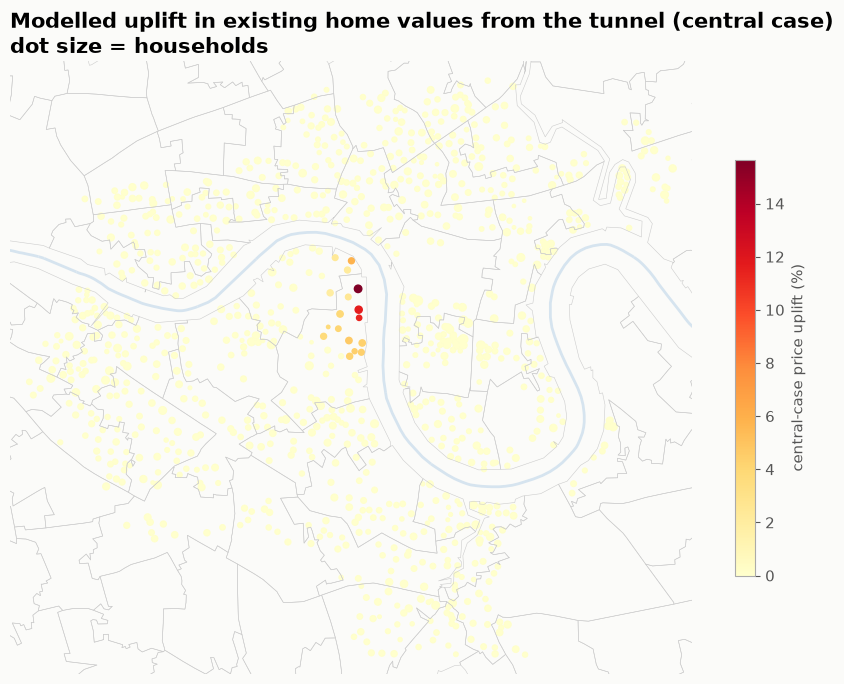

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9))
oa.plot(
    ax=ax,
    column=100 * oa["uplift_pct_Central"],
    cmap="YlOrRd",
    markersize=oa.households / 8,
    legend=True,
    vmin=0,
    legend_kwds={"label": "central-case price uplift (%)", "shrink": 0.6},
)
msoa.boundary.plot(ax=ax, color="#ccc", linewidth=0.4)
thames().plot(ax=ax, color=COLOURS["water"], linewidth=2)
xmin, ymin, xmax, ymax = oa.total_bounds
ax.set_xlim(xmin - 200, xmax + 200)
ax.set_ylim(ymin - 200, ymax + 200)
ax.set_axis_off()
ax.set_title("Modelled uplift in existing home values from the tunnel (central case)\ndot size = households")
fig.savefig(FIGURES / "uplift_map.png")